In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

In [2]:
data_path = Path.cwd().parent / "data/raw/bloomberg/"

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

In [3]:
def load_tenor(tenor):
    d = pd.read_csv(data_path / f"ovdv_impvol/SPX_IMPVOL_{tenor}.csv", parse_dates=True, index_col=0)
    d.columns = d.columns.str.extract(r"IMPVOL_([\d.]+)%")[0].astype(float)
    d.columns.name = "moneyness"
    return d

BAD_DATES = ["2022-09-20"]  # see 01_eda_series, step 2c

# no interpolation: filling t with t+1 would leak the target into the inputs
iv = load_tenor("30DAY")
iv.loc[BAD_DATES] = np.nan
d_iv = iv.diff()

In [4]:
TEST_START = "2021-01-01"
test = iv.index[iv.index >= TEST_START]

y = iv.loc[test]
pred_rw = iv.shift(1).loc[test]

In [5]:
def fit_ar1(s, end, window=None, robust=False):
    df = pd.concat([s, s.shift(1)], axis=1, keys=["y", "x"]).dropna()
    df = df[df.index < end]
    if window:
        df = df.iloc[-window:]
    X = sm.add_constant(df["x"])
    model = sm.RLM(df["y"], X, M=sm.robust.norms.HuberT()) if robust else sm.OLS(df["y"], X)
    return model.fit().params


def predict_ar1(window=None, robust=False):
    """Walk-forward AR(1) on daily changes, refit on the first day of each month."""
    pred = pd.DataFrame(index=test, columns=iv.columns, dtype=float)
    phi = pd.DataFrame(index=test.to_period("M").unique(), columns=iv.columns, dtype=float)
    for month, days in pd.Series(test, index=test).groupby(test.to_period("M")):
        for m in iv.columns:
            c, b = fit_ar1(d_iv[m], days.index[0], window, robust)
            pred.loc[days.index, m] = iv[m].shift(1).loc[days.index] + c + b * d_iv[m].shift(1).loc[days.index]
            phi.loc[month, m] = b
    return pred, phi

In [6]:
preds = {"persistence": pred_rw}
phis = {}
for name, kw in {
    "ar1_expanding": {},
    "ar1_rolling252": {"window": 252},
    "ar1_huber": {"robust": True},
    "ar1_rolling252_huber": {"window": 252, "robust": True},
}.items():
    preds[name], phis[name] = predict_ar1(**kw)

In [7]:
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

months = list(pd.Series(test, index=test).groupby(test.to_period("M")))


def lagged(df, nlags):
    return pd.concat([df.shift(k).add_suffix(f"_lag{k}") for k in range(1, nlags + 1)], axis=1)


def predict_ridge(nlags=1, window=None):
    """Each point's change regressed on lagged changes of all 9 points (discrete fLinK, Chen-Grith-Lai 2023)."""
    X = lagged(d_iv, nlags)
    data = pd.concat([d_iv, X], axis=1).dropna()
    pred = pd.DataFrame(index=test, columns=iv.columns, dtype=float)
    alphas = {}
    for month, days in months:
        train = data[data.index < days.index[0]]
        if window:
            train = train.iloc[-window:]
        model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 6, 29)))
        model.fit(train[X.columns], train[iv.columns])
        x = X.loc[days.index].dropna()
        pred.loc[x.index] = pred_rw.loc[x.index].to_numpy() + model.predict(x)
        alphas[month] = model[-1].alpha_
    return pred, pd.Series(alphas)


def predict_pca_var(n_factors=3, window=None):
    """VAR(1) on the first PCA factors of daily changes, mapped back to the 9 points."""
    pred = pd.DataFrame(index=test, columns=iv.columns, dtype=float)
    for month, days in months:
        train = d_iv[d_iv.index < days.index[0]].dropna()
        if window:
            train = train.iloc[-window:]
        pca = PCA(n_factors).fit(train)
        f = pd.DataFrame(pca.transform(d_iv.dropna()), index=d_iv.dropna().index).reindex(d_iv.index)
        xy = pd.concat([f, f.shift(1)], axis=1, keys=["y", "x"]).loc[train.index].dropna()
        X = np.column_stack([np.ones(len(xy)), xy["x"]])
        B = np.linalg.lstsq(X, xy["y"].to_numpy(), rcond=None)[0]
        f_prev = f.shift(1).loc[days.index].dropna()
        f_hat = np.column_stack([np.ones(len(f_prev)), f_prev]) @ B
        pred.loc[f_prev.index] = pred_rw.loc[f_prev.index].to_numpy() + pca.inverse_transform(f_hat)
    return pred

In [8]:
ridge_alphas = {}
for name, kw in {
    "ridge_lag1_expanding": {"nlags": 1},
    "ridge_lag1_rolling252": {"nlags": 1, "window": 252},
    "ridge_lag5_rolling252": {"nlags": 5, "window": 252},
}.items():
    preds[name], ridge_alphas[name] = predict_ridge(**kw)

preds["pca_var_expanding"] = predict_pca_var()
preds["pca_var_rolling252"] = predict_pca_var(window=252)

In [9]:
pd.DataFrame(ridge_alphas).describe().loc[["min", "50%", "max"]]

,ridge_lag1_expanding,ridge_lag1_rolling252,ridge_lag5_rolling252
min,56.234133,10.000000,31.622777
50%,177.827941,177.827941,1389.139705
max,177.827941,1000000.000000,1000000.000000


In [10]:
valid = y.notna().all(axis=1)
for p in preds.values():
    valid &= p.notna().all(axis=1)

errors = {name: (y - p)[valid] for name, p in preds.items()}
print(f"Evaluated days: {valid.sum()} ({y.index[valid][0]:%Y-%m-%d} to {y.index[valid][-1]:%Y-%m-%d})")

Evaluated days: 1440 (2021-01-04 to 2026-10-07)


In [11]:
def r2_oos(e, e_ref):
    return 1 - (e**2).to_numpy().sum() / (e_ref**2).to_numpy().sum()

summary = pd.DataFrame({
    name: {
        "mae": e.abs().to_numpy().mean(),
        "rmse": np.sqrt((e**2).to_numpy().mean()),
        "mae_vs_rw": e.abs().to_numpy().mean() / errors["persistence"].abs().to_numpy().mean() - 1,
        "r2_oos_vs_rw": r2_oos(e, errors["persistence"]),
    }
    for name, e in errors.items()
}).T
summary.round(4)

,mae,rmse,mae_vs_rw,r2_oos_vs_rw
persistence,0.9059,1.4527,0.0000,0.0000
ar1_expanding,0.9213,1.4528,0.0170,-0.0001
ar1_rolling252,0.9016,1.4340,-0.0047,0.0256
ar1_huber,0.9029,1.4389,-0.0033,0.0190
ar1_rolling252_huber,0.8975,1.4354,-0.0093,0.0237
ridge_lag1_expanding,0.9073,1.4394,0.0015,0.0182
ridge_lag1_rolling252,0.9053,1.4443,-0.0006,0.0116
ridge_lag5_rolling252,0.9143,1.4588,0.0092,-0.0084
pca_var_expanding,0.9189,1.4475,0.0144,0.0073
pca_var_rolling252,0.9155,1.4477,0.0106,0.0069


In [12]:
mae_by_moneyness = pd.DataFrame({name: e.abs().mean(axis=0) for name, e in errors.items()}).T
mae_by_moneyness.round(3)

moneyness,80.0,90.0,95.0,97.5,100.0,102.5,105.0,110.0,120.0
persistence,1.052,0.976,0.981,0.995,0.988,0.877,0.695,0.457,1.133
ar1_expanding,1.061,0.983,0.998,1.016,1.008,0.900,0.722,0.489,1.115
ar1_rolling252,1.049,0.971,0.980,0.994,0.987,0.876,0.695,0.456,1.107
ar1_huber,1.049,0.970,0.981,0.996,0.989,0.879,0.698,0.459,1.104
ar1_rolling252_huber,1.044,0.966,0.975,0.990,0.983,0.871,0.691,0.454,1.103
ridge_lag1_expanding,1.046,0.966,0.981,0.997,0.991,0.881,0.706,0.484,1.114
ridge_lag1_rolling252,1.051,0.975,0.980,0.995,0.990,0.879,0.697,0.461,1.119
ridge_lag5_rolling252,1.056,0.979,0.988,1.005,1.000,0.887,0.708,0.470,1.135
pca_var_expanding,1.049,0.972,0.987,1.004,1.000,0.897,0.731,0.516,1.114
pca_var_rolling252,1.065,0.988,0.994,1.008,1.002,0.892,0.710,0.469,1.112


In [13]:
mae_by_year = pd.DataFrame({name: e.abs().mean(axis=1).groupby(e.index.year).mean() for name, e in errors.items()})
mae_by_year.T.round(3)

date,2021,2022,2023,2024,2025,2026
persistence,1.024,1.163,0.732,0.710,0.984,0.807
ar1_expanding,1.013,1.223,0.741,0.748,0.985,0.797
ar1_rolling252,1.003,1.179,0.728,0.713,0.977,0.793
ar1_huber,0.999,1.181,0.728,0.725,0.975,0.792
ar1_rolling252_huber,0.999,1.165,0.726,0.711,0.976,0.792
ridge_lag1_expanding,0.991,1.210,0.728,0.720,0.972,0.808
ridge_lag1_rolling252,0.991,1.186,0.737,0.718,0.985,0.798
ridge_lag5_rolling252,1.019,1.192,0.739,0.732,0.985,0.799
pca_var_expanding,1.016,1.211,0.737,0.726,0.983,0.827
pca_var_rolling252,1.012,1.191,0.745,0.720,0.999,0.810


In [14]:
def diebold_mariano(e_ref, e, loss, maxlags=5):
    dl = loss(e_ref).mean(axis=1) - loss(e).mean(axis=1)
    res = sm.OLS(dl.to_numpy(), np.ones(len(dl))).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return res.tvalues[0], res.pvalues[0]

losses = {"squared": lambda e: e**2, "absolute": lambda e: e.abs()}
dm = pd.DataFrame({
    (name, loss_name): dict(zip(["t_stat", "p_value"], diebold_mariano(errors["persistence"], e, loss)))
    for name, e in errors.items() if name != "persistence"
    for loss_name, loss in losses.items()
}).T
dm.round(3)

t_stat  p_value
ar1_expanding         squared   -0.003    0.998
                      absolute  -1.715    0.086
ar1_rolling252        squared    1.832    0.067
                      absolute   0.799    0.424
ar1_huber             squared    0.957    0.339
                      absolute   0.441    0.659
ar1_rolling252_huber  squared    1.910    0.056
                      absolute   1.744    0.081
ridge_lag1_expanding  squared    0.753    0.451
                      absolute  -0.194    0.846
ridge_lag1_rolling252 squared    1.173    0.241
                      absolute   0.121    0.903
ridge_lag5_rolling252 squared   -0.565    0.572
                      absolute  -1.207    0.228
pca_var_expanding     squared    0.307    0.759
                      absolute  -1.782    0.075
pca_var_rolling252    squared    0.559    0.576
                      absolute  -1.901    0.057

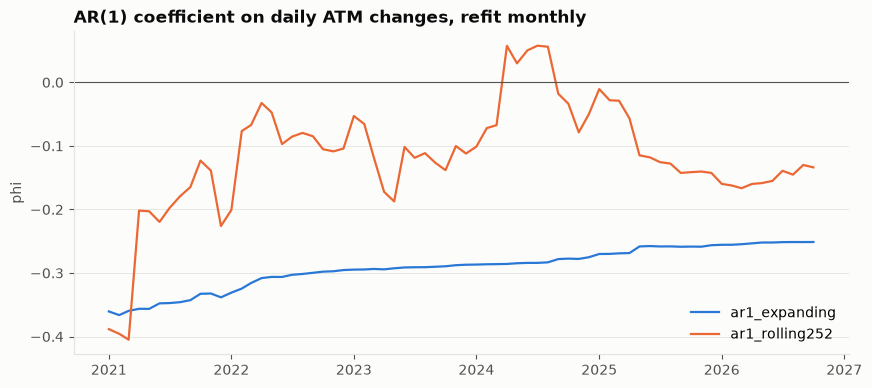

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color in zip(["ar1_expanding", "ar1_rolling252"], COLORS):
    phi = phis[name][100.0]
    ax.plot(phi.index.to_timestamp(), phi, color=color, label=name)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("AR(1) coefficient on daily ATM changes, refit monthly")
ax.set_ylabel("phi")
ax.legend()
plt.show()

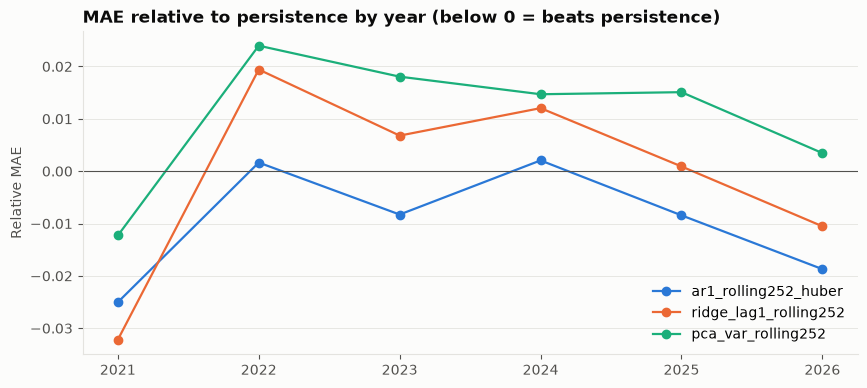

In [16]:
best = ["ar1_rolling252_huber", "ridge_lag1_rolling252", "pca_var_rolling252"]
rel = mae_by_year[best].div(mae_by_year["persistence"], axis=0) - 1

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color in zip(best, COLORS):
    ax.plot(rel.index, rel[name], marker="o", color=color, label=name)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("MAE relative to persistence by year (below 0 = beats persistence)")
ax.set_ylabel("Relative MAE")
ax.legend()
plt.show()

In [17]:
out_path = Path.cwd().parent / "data/processed"
out_path.mkdir(exist_ok=True)
pd.to_pickle(preds, out_path / "smile30_baseline_preds.pkl")